# Notebook 15 — Viva Preparation & Final Project Checklist

**Course:** 23CSE301 Machine Learning — Capstone Project, Review 1
**Inputs:** the result artifacts written by Notebooks 09 and 14

---

### What this notebook is for

Three things:

1. **A consolidated results dashboard** — every headline number from both
   tracks in one place, pulled from the saved artifacts rather than retyped,
   so it cannot drift out of date.
2. **38 viva questions with answers** grounded in *this* project's measured
   results, not generic textbook definitions. Where a question has a number
   attached, the number comes from our own output.
3. **The complete Review 1 self-audit checklist**, verified programmatically
   where possible.

> **A note on using this section.** The guidelines state that every team member
> must be able to explain any part of the work. These answers are written to be
> understood, not memorised — each one points back to the notebook and section
> where the evidence lives, so you can re-read the actual code and output
> behind it.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    ARTIFACT_DIR,
    FIGURE_DIR,
    ROOT,
    load_artifact,
    save_figure,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

reg = load_artifact("reg_09_final")
reg_tuned = load_artifact("reg_08_tuned")
clf = load_artifact("clf_14_results")

[loaded] artifacts/reg_09_final.joblib


[loaded] artifacts/reg_08_tuned.joblib
[loaded] artifacts/clf_14_results.joblib


---
## Part 1 — Consolidated Results Dashboard

In [2]:
section("REGRESSION TRACK — ALL 10 MODELS (Seoul Bike Sharing Demand)")
print(reg["comparison_table"].to_string(index=False))

REGRESSION TRACK — ALL 10 MODELS (Seoul Bike Sharing Demand)
 Rank                            Model     R2     RMSE      MAE
    1          Random Forest Regressor 0.9236 173.1930  92.4491
    2      Gradient Boosting Regressor 0.8964 201.6991 129.9858
    3 Polynomial Regression (degree 2) 0.8843 213.1268 143.1925
    4          Decision Tree Regressor 0.8560 237.7507 126.6929
    5                    KNN Regressor 0.8513 241.6550 146.9764
    6                 Lasso Regression 0.7108 336.9498 254.9703
    7                 Ridge Regression 0.7100 337.3982 255.6850
    8                Linear Regression 0.7100 337.4209 255.7086
    9            ElasticNet Regression 0.6575 366.6891 272.4767
   10   Support Vector Regressor (SVR) 0.3738 495.8196 331.7814


In [3]:
section("REGRESSION — HYPERPARAMETER TUNING")
print(reg["tuning_summary"][["Model", "Untuned test R2", "Tuned test R2",
                             "R2 gain", "RMSE saved (bikes)"]].to_string(index=False))

section("REGRESSION — 5-FOLD CROSS-VALIDATION OF THE TWO STRONGEST MODELS")
print(reg["cv_summary"][["Model", "CV mean R2", "CV std R2",
                         "CV min R2", "CV max R2", "Test R2"]].to_string(index=False))

section("REGRESSION — FINAL MODEL")
print(f"Model : {reg['best_model_name']}")
print(f"R²    : {reg['final_metrics']['R2']:.4f}")
print(f"RMSE  : {reg['final_metrics']['RMSE']:.1f} bikes")
print(f"MAE   : {reg['final_metrics']['MAE']:.1f} bikes")

REGRESSION — HYPERPARAMETER TUNING
        Model  Untuned test R2  Tuned test R2  R2 gain  RMSE saved (bikes)
Random Forest           0.9236         0.9298   0.0062                 7.2
          SVR           0.3738         0.9235   0.5497               322.5
REGRESSION — 5-FOLD CROSS-VALIDATION OF THE TWO STRONGEST MODELS
                Model  CV mean R2  CV std R2  CV min R2  CV max R2  Test R2
Random Forest (tuned)      0.9433     0.0046     0.9388     0.9511   0.9298
          SVR (tuned)      0.9228     0.0068     0.9138     0.9316   0.9235
REGRESSION — FINAL MODEL
Model : Random Forest (tuned)
R²    : 0.9298
RMSE  : 166.0 bikes
MAE   : 88.1 bikes


In [4]:
section("CLASSIFICATION PART A — ALL 5 MODELS (Adult / Census Income)")
print(clf["comparison_table"].to_string(index=False))

section("CLASSIFICATION — DETAILED METRICS")
print(clf["detail_table"][["Model", "Accuracy", "Weighted F1",
                           "Precision (>50K class)", "Recall (>50K class)",
                           "F1 (>50K class)"]].to_string(index=False))

section("CLASSIFICATION — BASELINE THAT EVERY MODEL MUST BEAT")
print(f"Always predict '<=50K':  Accuracy {clf['baseline']['Accuracy']:.4f}  |  "
      f"Weighted F1 {clf['baseline']['Weighted F1']:.4f}  |  "
      f"F1 on >50K {clf['baseline']['F1 (>50K class)']:.4f}")

CLASSIFICATION PART A — ALL 5 MODELS (Adult / Census Income)
 Rank                     Model  Accuracy  Weighted F1
    1       Logistic Regression    0.8589       0.8538
    2 Support Vector Classifier    0.8591       0.8520
    3       K-Nearest Neighbors    0.8410       0.8385
    4             Decision Tree    0.8265       0.8258
    5      Gaussian Naive Bayes    0.6752       0.6983
CLASSIFICATION — DETAILED METRICS
                    Model  Accuracy  Weighted F1  Precision (>50K class)  Recall (>50K class)  F1 (>50K class)
      Logistic Regression    0.8589       0.8538                  0.7518               0.6129           0.6753
Support Vector Classifier    0.8591       0.8520                  0.7721               0.5838           0.6649
      K-Nearest Neighbors    0.8410       0.8385                  0.6837               0.6249           0.6530
            Decision Tree    0.8265       0.8258                  0.6409               0.6253           0.6330
     Gaussian Naive 

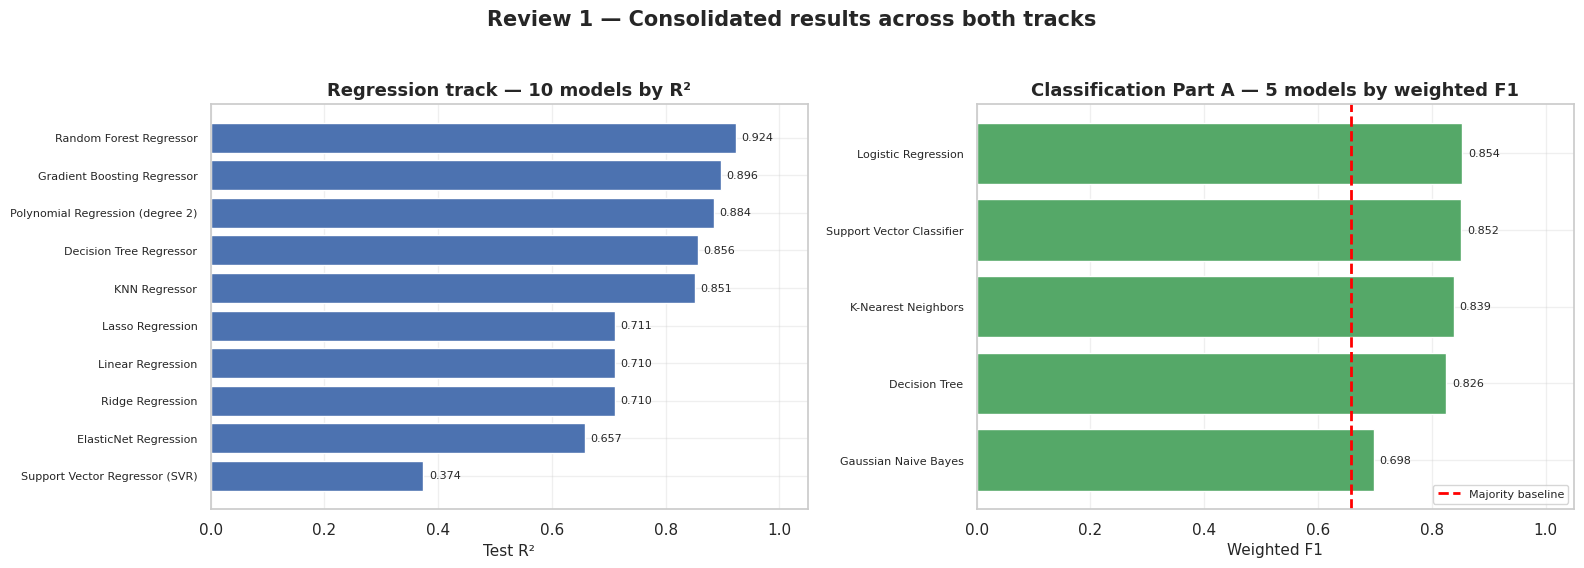

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

reg_tbl = reg["comparison_table"].sort_values("R2")
axes[0].barh(reg_tbl["Model"], reg_tbl["R2"], color="#4C72B0")
for i, v in enumerate(reg_tbl["R2"]):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)
axes[0].set_xlabel("Test R²")
axes[0].set_xlim(0, 1.05)
axes[0].set_title("Regression track — 10 models by R²")
axes[0].tick_params(axis="y", labelsize=8)

clf_tbl = clf["comparison_table"].sort_values("Weighted F1")
axes[1].barh(clf_tbl["Model"], clf_tbl["Weighted F1"], color="#55A868")
for i, v in enumerate(clf_tbl["Weighted F1"]):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)
axes[1].axvline(clf["baseline"]["Weighted F1"], color="red", ls="--", lw=2,
                label="Majority baseline")
axes[1].set_xlabel("Weighted F1")
axes[1].set_xlim(0, 1.05)
axes[1].set_title("Classification Part A — 5 models by weighted F1")
axes[1].tick_params(axis="y", labelsize=8)
axes[1].legend(fontsize=8, loc="lower right")

fig.suptitle("Review 1 — Consolidated results across both tracks",
             y=1.03, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("final_dashboard", fig)
plt.show()

---
## Part 2 — Viva Questions & Answers

Thirty-eight questions covering every topic listed in the project brief. Section
references point to the notebook where the supporting evidence lives.

### A. Project design and datasets

---

**Q1. Why did you choose these two datasets?**

They were assigned for the two tracks, and they suit their tasks well. Seoul
Bike Sharing has a continuous numeric target (`Rented Bike Count`, 0–3,556)
with strong non-linear structure — ideal for demonstrating why ten different
regression algorithms behave differently. Adult/Census Income has a genuinely
binary target with moderate class imbalance (3.18 : 1), which forces us to
engage with the difference between accuracy and F1 rather than just reporting
one number.

Crucially, **we never merge them.** They are two entirely separate ML problems
with separate notebooks, splits, pipelines, metrics and conclusions.

---

**Q2. Why is the bike problem regression and the income problem
classification?**

The target determines the task type.

`Rented Bike Count` is a **continuous numeric quantity**. Predicting 900 when
the truth is 890 is nearly harmless; predicting 100 is not. Error cost scales
with distance, which is exactly what R², RMSE and MAE measure.

`income` is a **label from a fixed set of two categories**. There is no
meaningful sense in which one wrong label is "closer" than another — it is
either right or wrong. So we count correct and incorrect labels: accuracy,
precision, recall, F1, confusion matrix.

Applying regression metrics to a classification target would be meaningless:
R² assumes a numeric distance between prediction and truth, and class labels
have none.

---

**Q3. Why did you choose those particular targets?**

Both were specified by the problem statement, and both are the operationally
meaningful quantity. For the bike system, `Rented Bike Count` is what
determines how many bicycles must be deployed. For the census data, the >50K
threshold is the standard benchmark formulation of the Adult dataset.

---

**Q4. Why did you remove 295 rows from the bike dataset?**

Those are the hours when `Functioning Day == "No"` — the rental system was
closed. On every one of them the target is **exactly 0, with zero variance**
(Notebook 02 §4.6). That is not low demand; it is an administrative rule.

Keeping them would let every model gain apparent accuracy by learning "if
closed then 0", inflating R² without learning anything about human behaviour.
We removed them and then dropped the `Functioning Day` column, which had
become constant and therefore carried zero information.

This is the **only** row removal in the entire regression track. No value was
clipped, winsorised or altered anywhere (Notebook 04 §6.7).

### B. Splitting, reproducibility and leakage

---

**Q5. Why split into train and test at all?**

Because a model's score on data it was trained on tells you almost nothing
about how it will perform on new data. Our Decision Tree is the perfect
demonstration: it scored **R² = 1.0000 on the training set** and 0.8560 on the
test set (Notebook 07). It had memorised the training rows. Without a held-out
test set we would have reported a perfect model.

---

**Q6. Why `random_state=42`?**

To make the work reproducible. `train_test_split`, the tree-based models and
the hyperparameter searches all involve randomness. Fixing the seed means
anyone re-running these notebooks gets **exactly** the numbers reported here.
Without it, every re-run would produce slightly different results and no claim
could be verified.

There is nothing special about 42 — it is a convention. What matters is that
it is fixed and stated.

---

**Q7. Why is the classification split stratified but the regression split not?**

Stratification preserves **class proportions**, and only a classification
target has classes. With a 76/24 split, an ordinary random split could hand
the test set a noticeably different class balance by chance, making model
comparisons unreliable. `stratify=y` prevents that: our split matches the full
dataset to within **0.006 percentage points** (Notebook 13 §7.2).

A continuous target has no classes to stratify on. We verified instead that
the train and test target distributions matched (Notebook 06 §8.3).

---

**Q8. What is data leakage, and how did you prevent it?**

Data leakage is when information from the test set influences the training
process. The model is then evaluated on data it has already been exposed to,
and the reported score is optimistically biased.

The classic example: if you fit a `StandardScaler` on the full dataset before
splitting, the scaler's mean and standard deviation contain information from
the test rows. Every training row is then scaled using knowledge of the test
set.

Our defences (Notebook 06 §8.6, Notebook 13 §8.4):

1. **Split first.** The first `.fit()` call anywhere happens after the split.
2. **All transformations live inside a `Pipeline`.** When
   `pipeline.fit(X_train)` runs, the scaler fits on training rows only; when
   `pipeline.predict(X_test)` runs, it only transforms. This holds inside every
   cross-validation fold too.
3. **No target-derived features.** We explicitly rejected target/mean encoding
   in both tracks.
4. **No lag features in the bike data**, because under a random split the
   lagged row often lands in the other split.
5. **Tuning used cross-validation on training data only.** The test set was
   never used to select a hyperparameter.

---

**Q9. Can you *prove* you avoided leakage?**

Yes, and we printed the proof. In Notebook 06 §8.5 and Notebook 13 §8.3 the
scaling sanity check shows:

* training columns: mean exactly **0.0000**, std exactly **1.0000**
* test columns: **close to but not exactly** 0 and 1

That small discrepancy is the evidence. The test set was standardised using
the *training* mean and standard deviation, so it lands near but not on those
values. **If the test set had also come out at exactly 0 and 1, the scaler
would have been fitted on it — that would be leakage.** A perfectly scaled
test set is a red flag, not a success.

---

**Q10. You engineered features before splitting. Isn't that leakage?**

No, and the distinction is precise. Every engineered feature is computed
**row-wise from that row's own values**: `Month` comes from that row's date,
`sin_hour` from that row's hour, `has_capital_gain` from that row's
capital-gain. No dataset-wide statistic is involved, so no information can
cross between rows.

A feature like "average demand for this hour" **would** leak, because the
average would be computed over rows that end up in the test set. We rejected
every such candidate (Notebook 05 §7.6, Notebook 13 §6.8).

Anything requiring a `.fit()` — scaling, encoding, statistical imputation — is
deferred to the pipeline, after the split.

---

**Q11. Why use `Pipeline` and `ColumnTransformer` instead of transforming the
data manually?**

Three reasons, in order of importance:

1. **It makes leakage structurally difficult.** Fit/transform discipline is
   enforced by the object rather than by remembering to do it right.
2. **It works correctly inside cross-validation.** When `cross_val_score`
   receives a whole pipeline, the preprocessing is refitted on each training
   fold. Manual preprocessing before CV would leak the validation fold into its
   own scaling — a subtle error that is very easy to make.
3. **`ColumnTransformer` routes columns by type**, applying scaling to numeric
   columns and one-hot encoding to categorical ones in a single object. The
   saved final model is one artifact that can `.predict()` on raw data — there
   is no separate scaler to remember to apply.

### C. Preprocessing decisions

---

**Q12. Why scale features, and which models actually needed it?**

Scaling puts every feature on a comparable range. It matters because some
algorithms measure distance and some do not.

**Needed it:**

* **KNN** — classifies by Euclidean distance. Unscaled, `capital-gain`
  (range 0–99,999) would dominate `education-num` (range 1–16) entirely.
* **SVR / SVC** — the RBF kernel is a function of Euclidean distance; same
  problem.
* **Ridge / Lasso / ElasticNet** — the penalty is applied to coefficient
  magnitudes, which are only comparable if features share a scale.

**Did not need it:**

* **Decision Trees** — scale-invariant. They split on thresholds, and any
  monotonic rescaling leaves the ordering of rows unchanged.
* **Gaussian Naive Bayes** — estimates a mean and variance per feature.

We **measured** this rather than asserting it (Notebook 14 §11.2), and one
result surprised us. The Decision Tree was **unchanged** without the scaler, as
theory requires. But **KNN got slightly better** (0.8385 → 0.8480).

The explanation is that our feature space is 79 one-hot columns and only 9
numeric ones. `StandardScaler` divides by each column's standard deviation, and
a **rare** one-hot category has a tiny standard deviation — so scaling
*inflates* it. Two people differing only in a rare occupation can end up
further apart than two people twenty years apart in age. We report this as
measured: the textbook argument for scaling KNN is correct for mostly-continuous
data, but **the effect depends on the composition of the feature space**, and a
rule of thumb should be checked rather than assumed.

---

**Q13. Why one-hot encoding rather than label encoding?**

Label encoding assigns integers to categories — Winter = 0, Spring = 1,
Summer = 2, Autumn = 3. That tells every linear, distance and kernel model
that Autumn is "three times" Spring and that Summer sits exactly between
Spring and Autumn. Those are arithmetic claims about categories that have no
numeric order.

One-hot encoding creates a separate binary column per category and makes no
such claim. The cost is more columns — 88 features in the classification
track — which is why we grouped `native-country` from 41 levels down to 3.

---

**Q14. Why `handle_unknown="ignore"` in the encoder?**

Because a category present in the test set but absent from training would
otherwise raise an error at predict time. This is a real risk here, not a
formality: Notebook 11 §3.3 found categories with as few as **10 rows**
(`Never-worked`) and 15 (`Armed-Forces`). With a random split those can easily
fall entirely on one side. `handle_unknown="ignore"` maps an unseen category to
an all-zero row instead of crashing.

---

**Q15. You have zero missing values in the bike data — why keep an imputer?**

Robustness. The imputer costs nothing when there is nothing to impute, but if
this pipeline were ever fed a live weather feed with a dropped sensor reading,
it would handle it instead of crashing. A pipeline that only works on perfectly
clean input is fragile.

---

**Q16. How did you handle the missing values in the Adult dataset, and why?**

We **encoded them as a category called `"Unknown"`** rather than dropping or
imputing (Notebook 13 §5).

The reasoning comes from the audit. `workclass` and `occupation` are missing
**together in every single case** — all 2,799 rows missing `workclass` are also
missing `occupation`. Those people are slightly older (40.1 vs 38.6), work far
fewer hours (31.8 vs 40.9), and earn >50K at **9.5% against 24.8%** for
complete records. They are a recognisable group: people not currently employed.

So the missingness is **informative, not random**:

* **Dropping** them would delete 7.41% of the data and remove a distinct
  population, biasing the model towards the employed.
* **Imputing the mode** would assert that a retiree works in the private sector
  as a professional — something the data contradicts — and destroy the signal.
* **Encoding as `"Unknown"`** preserves the signal and invents nothing. The
  output confirms it worked: `Unknown` has one of the lowest income rates of
  any category, so it is genuinely predictive.

### D. Metrics

---

**Q17. What is the difference between R², RMSE and MAE?**

| Metric | What it measures | Units | Reading |
|---|---|---|---|
| **R²** | Proportion of variance in the target explained by the model | none (0–1 typically) | 1.0 = perfect; 0 = no better than predicting the mean; negative = worse than the mean |
| **RMSE** | Square root of the mean squared error | same as target (bikes) | Penalises large errors disproportionately |
| **MAE** | Mean of absolute errors | same as target (bikes) | The typical error size; treats all errors proportionally |

Our final model: **R² = 0.9298, RMSE = 166.0, MAE = 88.1**. The R² says we
explain 93% of the variance; the MAE says we are typically off by about 88
bikes against a mean demand of 720 — roughly 12%.

The three are complementary. R² is comparable across problems but is not in
any real unit. MAE is directly interpretable ("we are off by 88 bikes"). RMSE
is the one to optimise if large errors are disproportionately costly.

---

**Q18. Why is RMSE always larger than MAE in your results?**

Mathematically, RMSE ≥ MAE always, with equality only if every error is
identical. RMSE squares the errors before averaging, so a few large errors
dominate the result.

The **size of the gap** is therefore a diagnostic of error spread. In our
results the ratio ranges from about 1.3× (Linear Regression) to 1.9× (Random
Forest). Random Forest having the *highest* ratio tells us something useful:
its typical prediction is excellent (MAE just 88 bikes) but it still misses
badly on a small number of extreme hours.

We predicted this in Notebook 02 before fitting anything, from the target's
right skew (+1.15).

---

**Q19. What is accuracy, and why is weighted F1 better here?**

Accuracy is the proportion of predictions that are correct. Its weakness is
that it treats every prediction equally, so on an imbalanced dataset it is
dominated by the majority class.

In our data, **a model that predicts `<=50K` for every single person scores
0.7607 accuracy** while learning absolutely nothing. That is the floor every
result must be read against.

**Weighted F1** computes the F1 score separately for each class and averages
them weighted by class support. F1 is the harmonic mean of precision and
recall, and the harmonic mean is dragged down hard by whichever is worse. The
always-`<=50K` model scores **0.0000 F1 on the >50K class**, giving a weighted
F1 of 0.6573 — a full 10 points below its accuracy for the same predictions.
F1 catches exactly the failure that accuracy conceals.

---

**Q20. Why can two models have similar accuracy but different F1?**

**This happened in our own results, which is the best possible answer.**

SVC scored 0.8591 accuracy and Logistic Regression 0.8589 — a difference of
0.0002. But Logistic Regression has the **higher weighted F1**. The two models
swap rank depending on the metric.

The reason is visible in the minority-class columns: SVC has higher precision
but **lower recall** on >50K. It is the more conservative model, predicting
`>50K` only when confident. That buys majority-class accuracy at the cost of
missing more high earners — and weighted F1, which incorporates recall, notices
what accuracy averages away.

The most dramatic case is Gaussian Naive Bayes: **last on accuracy** (0.6752,
below the baseline) but with **by far the highest recall on >50K (0.9239)**. It
finds more high earners than any other model, at the cost of many false alarms.

---

**Q21. What does a confusion matrix show, and what do false positives and
false negatives mean here?**

It is a table of true label against predicted label. With `>50K` as the
positive class:

| | Predicted ≤50K | Predicted >50K |
|---|---|---|
| **Actually ≤50K** | True Negative | **False Positive** |
| **Actually >50K** | **False Negative** | True Positive |

* **False Positive** = a lower earner wrongly flagged as high-income.
* **False Negative** = a higher earner missed.

Which is worse depends entirely on the application. For **targeting a support
programme at lower earners**, a false positive is damaging — someone who
qualifies for help is excluded. For **research into what characterises high
earners**, false negatives bias every conclusion. For **credit or hiring**,
both are serious, and this model should not be used at all (Notebook 10 §1.7).

A single accuracy figure collapses these very different harms into one number.
That is why the confusion matrix is required.

### E. Regression algorithms

---

**Q22. What is the difference between Ridge, Lasso and ElasticNet?**

All three are Linear Regression plus a penalty on coefficient size.

| | Penalty | Effect | Use when |
|---|---|---|---|
| **Ridge** | L2 — sum of *squared* coefficients | Shrinks coefficients towards zero, never exactly to zero | Many correlated predictors |
| **Lasso** | L1 — sum of *absolute* coefficients | Can drive coefficients to **exactly zero** → automatic feature selection | You want a sparse model |
| **ElasticNet** | Mix of both, controlled by `l1_ratio` | Shrinks correlated groups together | Correlated predictors *and* you want sparsity |

**In our results all three scored almost identically to plain Linear
Regression** (0.7108, 0.7100, 0.7100), and ElasticNet was *worse* (0.6575).

That result is itself the interesting part. Regularisation helps when a model
is **overfitting** — but with 6,772 rows and only 33 features, our linear
models were **underfitting**. There was no excess variance to shrink, so the
penalty had nothing useful to do, and ElasticNet's stronger combined penalty
actively over-shrank. **No amount of regularisation fixes a model that is too
simple for the data.**

Lasso did demonstrate its feature-selection property: it drove 4 of 33
coefficients to exactly zero, including `Dew point temperature`, which
correlates 0.91 with `Temperature`.

---

**Q23. Why include Polynomial Regression, and what did comparing degrees show?**

It was included because the EDA found relationships a straight line cannot
represent — most clearly an **inverted-U temperature curve**, where demand
rises to about 30 °C and then falls. `PolynomialFeatures` expands the feature
matrix with powers and interaction products, letting a *linear* algorithm fit
a *non-linear* shape.

We selected the degree by **3-fold cross-validation on the training set only**:

| Degree | Features generated | CV R² |
|---|---|---|
| 1 | 33 | 0.715 |
| 2 | 594 | **0.879** |
| 3 | 7,139 | ≈ **−6 × 10⁸** |

Degree 2 was selected and reached 0.8843 on the test set — up 0.17 from Linear
Regression with the *same algorithm and the same features*, which isolates
functional form as the reason the linear family struggled.

**Degree 3 is the more instructive result.** With 7,139 features fitted to
6,772 training rows — more parameters than observations — it fits the training
data almost perfectly but oscillates wildly between the training points, so
predictions on unseen data are nonsense. It is a textbook demonstration of
overfitting, and note that **cross-validation on the training set alone was
enough to reject it.** We never needed the test set.

---

**Q24. Decision Tree vs Random Forest — what is the difference and why does it
matter?**

A **Decision Tree** recursively splits the feature space and predicts the mean
(regression) or majority class (classification) of each leaf. It models
non-linearity and interactions natively, and it is interpretable. Its weakness
is **high variance**: grown unpruned, it splits until every leaf is pure.

A **Random Forest** trains many trees, each on a bootstrap sample of the rows
and considering a random subset of features at each split, then averages them.
The randomness decorrelates the trees so their individual errors partly cancel.

**Our measured evidence for why this matters:**

| | Train R² | Test R² |
|---|---|---|
| Decision Tree | **1.0000** | 0.8560 |
| Random Forest | 0.9920 | **0.9236** |

The single tree achieved a *perfect* training score — it memorised the data —
and lost 0.144 on the test set. The forest, built from the same kind of trees,
lost only 0.068. **That difference is the value of ensembling, measured.**

The same pattern appeared in the classification track: the Decision Tree had
the largest train/test gap of all five models.

---

**Q25. Random Forest vs Gradient Boosting?**

Both are tree ensembles, but they combine trees in opposite ways:

* **Random Forest** builds trees **in parallel and independently**, then
  averages them. This targets **variance** — each tree overfits differently and
  the errors cancel.
* **Gradient Boosting** builds trees **sequentially**, each fitted to the
  residuals of the ensemble so far. This targets **bias** — each tree corrects
  its predecessors.

In our results Random Forest scored 0.9236 and Gradient Boosting 0.8964 — but
**this comparison is not like-for-like, and we should say so.** Random Forest
was given 300 trees; Gradient Boosting was left at its default of 100 shallow
trees (`max_depth=3`). A well-tuned GBM frequently beats a Random Forest on
tabular data. Our result shows that *at these settings* the forest won, not
that boosting is inferior.

---

**Q26. What is SVR, and why did it fail so badly before tuning?**

Support Vector Regression fits a tube of width `epsilon` around the data and
penalises only points **outside** it, with `C` controlling how heavily. The RBF
kernel allows a non-linear fit.

Untuned, SVR was our **worst model at R² = 0.3738**. The cause is specific and
diagnosable: the defaults are `epsilon=0.1` and `C=1.0`, which suit a target of
magnitude around 10. **Our target reaches 3,556.** The model was effectively
told that being wrong by hundreds of bikes barely matters.

We built the tuning grid directly around that diagnosis, and it was confirmed:
the winning configuration was `C=1000, epsilon=10, gamma=0.1`, lifting SVR from
**0.3738 to 0.9235** — from last place to competitive with the ensembles.

Note the contrast with SVC in the classification track, where the defaults
worked fine. A classifier outputs a label, not a quantity whose magnitude must
match the target's scale, so it does not have this problem.

---

**Q27. Why does KNN need scaling?**

KNN predicts from the `k` nearest training points, measured by Euclidean
distance. Distance sums the squared differences across all features, so a
feature with a large numeric range contributes far more than one with a small
range — regardless of how predictive either is.

In our bike data, `Visibility` runs 27–2000 while `Snowfall` rarely exceeds 1.
Unscaled, "nearest hour" would mean "hour with the most similar visibility",
and every other feature would be effectively ignored. In the Adult data,
`capital-gain` (0–99,999) would swamp `education-num` (1–16), even though
education is by far the stronger predictor.

We confirmed this by experiment in Notebook 14 §11.2: removing the scaler
damaged KNN more than any other model.

### F. Classification algorithms

---

**Q28. Explain Logistic Regression, Gaussian Naive Bayes, KNN, Decision Tree
and SVC — and how did each perform?**

**Logistic Regression** models the log-odds of the positive class as a weighted
sum of features, squashed through a sigmoid into a probability. Its
coefficients are interpretable as log-odds. It cannot represent non-linearity
or interactions.
*Result: joint-strongest, and the highest weighted F1.* This was not the
obvious prediction, since the EDA found a non-monotonic age effect. Two things
rescued it: the strongest predictors here are **categorical**, which one-hot
encoding handles perfectly for a linear model, and the **banded features** we
engineered (`age_band`, `hours_band`) handed it piecewise approximations of
exactly the curves it could not otherwise fit. A demonstration that feature
engineering can substitute for model complexity.

**Gaussian Naive Bayes** applies Bayes' theorem assuming every feature is
conditionally independent given the class, and that numeric features are
normally distributed within each class.
*Result: weakest on accuracy (0.6752), as we predicted in advance.* Both
assumptions are demonstrably false here — EDA §4.7 measured clear interactions
between age and hours and between education and sex, and 88 binary one-hot
columns are about as far from Gaussian as a variable can be. **But it had by
far the highest recall on the minority class (0.9239)**, which makes it the
most useful model if missing a high earner is costly.

**KNN** classifies by majority vote among the `k` nearest neighbours. No
assumptions about functional form.
*Result: mid-table, exactly as predicted.* With 88 mostly-sparse binary
columns, Euclidean distances become less discriminative — the curse of
dimensionality.

**Decision Tree** splits recursively on the feature that best separates classes
by Gini impurity. Models interactions natively; scale-invariant.
*Result: underperformed, with the largest train/test gap of the five.* Unpruned,
it memorised the training set. Our EDA hypothesis explicitly flagged this as
the uncertain case — flexibility versus variance — and variance won.

**SVC** finds the maximum-margin boundary, with the RBF kernel allowing a
non-linear one. Needs scaled features.
*Result: highest accuracy (0.8591), but not the highest weighted F1.* It has
the highest precision and lowest recall on >50K — the most conservative model.
Also by far the slowest to train, since cost grows roughly quadratically with
39,073 training rows.

---

**Q29. What is the conditional independence assumption, and does it hold?**

Naive Bayes assumes that, **given the class**, every feature is independent of
every other. Formally it computes P(features | class) as the simple product of
P(each feature | class).

**It does not hold here, and we measured that before fitting the model.** EDA
§4.7 showed that the effect of working 50+ hours on income depends strongly on
age, and that the education–income relationship differs by sex. Those are
interactions — the definition of dependence. `relationship` also largely
restates `marital-status`.

This gave us a falsifiable prediction, and it was confirmed: Naive Bayes was
the weakest model on accuracy.

It is worth noting that Naive Bayes often works well *despite* violated
assumptions, because it only needs to get the *ranking* of class probabilities
right, not their absolute values. Here the violations were severe enough to
hurt.

### G. Validation, tuning and model behaviour

---

**Q30. What is cross-validation, and what did it tell you?**

A single 80/20 split gives one number from one sample. Cross-validation splits
the **training data** into k folds, trains on k−1 and validates on the
remaining one, k times. The **mean** estimates typical performance; the
**standard deviation** measures stability.

Our 5-fold results (Notebook 08 §12):

| Model | CV mean R² | CV std | Fold range | Test R² |
|---|---|---|---|---|
| Random Forest (tuned) | 0.9433 | 0.0046 | 0.9388–0.9511 | 0.9298 |
| SVR (tuned) | 0.9228 | 0.0068 | 0.9138–0.9316 | 0.9235 |

Three conclusions:

1. **Both are stable** — standard deviation under 1% of the mean, so
   performance does not depend on which rows the model happened to see.
2. **Random Forest's advantage is real, not noise** — the two ranges do not
   overlap.
3. **The test scores are consistent with the CV estimates.** Random Forest's
   test score is 0.0134 *below* its CV mean, which is the safe direction to err
   in and is expected, since the tuned parameters were selected to maximise CV
   score.

Crucially, **the test set is never involved in cross-validation** — it runs
entirely within the training data.

---

**Q31. Why tune hyperparameters, and did it help?**

Hyperparameters are settings chosen *before* training (unlike parameters, which
are learned). Defaults are generic and may badly mismatch a specific problem.

**Our two models responded completely differently, and the contrast is the real
lesson:**

| Model | Untuned R² | Tuned R² | Gain |
|---|---|---|---|
| SVR (GridSearchCV, 18 candidates) | 0.3738 | **0.9235** | **+0.5497** |
| Random Forest (RandomizedSearchCV, 20 candidates) | 0.9236 | 0.9298 | +0.0062 |

**SVR gained enormously** because its defaults were mis-scaled for our target
(see Q26). **Random Forest barely moved** because it is famously insensitive to
its hyperparameters — averaging hundreds of decorrelated trees already controls
variance, leaving the per-tree knobs little to do.

**Tuning is not a uniform improvement.** Its value depends on how sensitive the
algorithm is and how badly the defaults match the problem. Reporting the case
where it achieved almost nothing is part of an honest account.

---

**Q32. GridSearchCV or RandomizedSearchCV — how did you choose?**

`GridSearchCV` tries every combination exhaustively. `RandomizedSearchCV`
samples a fixed number at random.

We used **both, matched to the size of the space**:

* **SVR: GridSearchCV.** Only 18 combinations — small enough to try them all
  and guarantee we see the best one.
* **Random Forest: RandomizedSearchCV.** The grid had **432 combinations**,
  which at 3 folds would be 1,296 model fits. We sampled 20. With a space that
  large, random sampling explores the important dimensions more efficiently
  than an exhaustive grid of the same budget, because it tries many distinct
  values of each parameter rather than repeating a few.

Both searched using **cross-validation on the training set only**. The test set
was never used to select a parameter.

---

**Q33. What are overfitting and underfitting, and where did you see each?**

**Overfitting** — the model learns noise specific to the training data and
generalises poorly. Symptom: training score far above test score.

**Underfitting** — the model is too simple to capture the real structure.
Symptom: both scores low, and close together.

**We have clean examples of both:**

*Overfitting:* the unpruned Decision Tree scored **R² = 1.0000 on train** and
0.8560 on test. Polynomial degree 3 was even more extreme: 7,139 features for
6,772 rows, giving a CV R² around **−6 × 10⁸**.

*Underfitting:* Linear Regression scored 0.7173 on train and 0.7100 on test —
barely any gap, but both modest. It is not memorising anything; it is
structurally unable to represent the inverted-U and threshold relationships the
EDA found. Gaussian Naive Bayes is the classification-track equivalent: train
and test scores both low and nearly identical.

The contrast is the **bias–variance trade-off**: the tree has low bias and high
variance, Linear Regression and Naive Bayes have high bias and low variance,
and neither extreme is what we want.

---

**Q34. Your correlation analysis showed rainfall at only −0.12. Why keep it?**

Because **Pearson's r measures only linear association**, and the rainfall
effect is not linear.

The measured relationship (Notebook 03 §5.E): mean demand falls from **766
bikes in dry hours to 251** in the 0–0.5 mm band — losing two-thirds of its
volume at the first drop of rain — then declines only gradually across heavier
bands (134, 101, 73).

That is a **threshold effect**. Correlation, looking for a proportional slope
across the whole range, reports it as nearly zero. Rainfall is genuinely
important; correlation simply cannot see it.

**The general lesson: a low correlation is not evidence of low importance.** We
added an `IsRaining` binary flag to give linear models direct access to the
threshold, and the tree models found it on their own.

---

**Q35. Why did you keep the outliers in the bike data?**

Because they are real. The IQR rule flagged 152 hours (1.80%) above the upper
fence, and we investigated them rather than deleting them (Notebook 04 §6.5):

* **86 occur at 18:00 and 34 at 19:00** — 79% fall in the evening commute window.
* **Not one occurs in Winter.**
* They average **24.3 °C against 12.6 °C** and **0.00 mm of rain against 0.15 mm**.

Every property matches what domain knowledge predicts for peak demand: warm,
dry evening rush hours. These are **genuine high-demand observations**, and
they are the most operationally important hours in the dataset — a model that
cannot predict the 18:00 summer peak is useless for fleet planning.

Deleting them would also have caused **optimistic bias**: both training and
test sets would lose their hardest cases, so the reported R² would overstate
real performance. That is manipulating the data to get a better score.

We also showed that IQR is the **wrong tool** for `Rainfall` and `Snowfall`:
when a variable is zero more than 75% of the time, Q1 and Q3 are both zero, the
IQR is zero, and every non-zero value is automatically flagged. The method was
not detecting anomalies — it was detecting that it sometimes rains.

---

**Q36. Can you claim your feature importances show what *causes* bike demand,
or income?**

**No.** Feature importance measures how much a *model* relies on a variable. It
does not establish causation. These are observational data with no experiment
and no randomisation.

Three concrete reasons this is not a formulaic caveat:

1. **Confounding.** `Temperature` ranks first, but it is entangled with hour,
   season and daylight. Notebook 05 §7.5 showed the temperature effect looked
   much weaker until we controlled for hour.
2. **Proxy variables.** `Hour` does not cause anyone to cycle. It proxies for
   work and school schedules — the actual causes, which are absent from the data.
3. **Correlated features split their credit.** `Temperature` and `Dew point`
   correlate at 0.91, so a tree picks one arbitrarily at each split. Their
   individual scores are partly an artefact of that choice.

In the income track this matters even more, because the variables describe
people. **Marital status ranking first does not mean marriage raises income** —
it is confounded with age and career stage. And where `race` or `sex` carry
importance, the model is recording **1994 disparities**, not discovering a
property of people (Notebook 10 §1.7, Notebook 14 §11.3).

What we *can* say: given the available information, these are the variables the
model depends on most to predict accurately. That is a statement about
prediction, not explanation.

---

**Q37. Your Random Forest gets R² = 0.93. Would it forecast next month's demand
that well?**

**Probably not, and this is the most important limitation in the project.**

We used a **random** train/test split, as the assignment specifies. But the
data is an hourly **time series** with strong temporal autocorrelation
(Notebook 03 §5.F.4) — today's demand resembles yesterday's. A random split
interleaves training and test hours in time, so the model can see hours from
the same day on both sides.

Our R² therefore answers **"how well does the model explain demand given
weather and calendar conditions?"** — not **"how well would it forecast next
month?"** For a production forecasting system, a **chronological** split or
`TimeSeriesSplit` would be the honest evaluation.

We flagged this in Notebook 03, again in Notebook 06 §8.3, and listed it as
limitation 1 in Notebook 09 §13.8, rather than quietly benefiting from it.

---

**Q38. Which of your two final models is best?**

We deliberately **do not** declare an overall winner in either track, and the
reasons differ.

**Regression:** Random Forest was selected, and the evidence supports it — its
CV mean of 0.9433 ± 0.0046 does not overlap with SVR's 0.9228 ± 0.0068. But we
state it as "the best of the ten algorithms tested, on this dataset, under this
split, by these metrics", not as an absolute claim. Notebook 09 §13.8 lists ten
conditions under which it would not hold.

**Classification:** we explicitly decline to name a winner. The top two are
separated by **0.0002 in accuracy**, they **swap rank** depending on whether
you use accuracy or weighted F1, none has been tuned, and there is no
cross-validation. Declaring a winner on that evidence would be a claim the
measurements do not support. Establishing one is Review 2 work.

---
## Part 3 — Review 1 Self-Audit Checklist

Verified programmatically where possible.

In [6]:
checks_regression = [
    ("Dataset loaded", "NB 01 §3.1 — SeoulBikeData.csv, cp1252 encoding, 8,760 rows"),
    ("Target correctly defined", "NB 01 §1.5 — Rented Bike Count"),
    ("Shape shown", "NB 01 §3.4"),
    ("Data types shown", "NB 01 §3.4, §3.5 (info())"),
    ("Missing values checked", "NB 02 §4.1 — 0 NaN + explicit placeholder check"),
    ("Duplicates checked", "NB 02 §4.2 — 0 full duplicates, 0 duplicate (Date,Hour)"),
    ("Target distribution shown", "NB 02 §4.7, NB 03 §5.A — histogram, KDE, boxplot"),
    ("Feature distributions shown", "NB 03 §5.B — all 9 numeric features"),
    ("Correlation heatmap shown", "NB 03 §5.D"),
    ("At least 2 feature-target plots", "NB 03 §5.E — 4 plots"),
    ("EDA interpretations written", "NB 03 — every figure followed by Markdown"),
    ("Outliers investigated", "NB 04 §6.2-6.6 — boxplots, IQR, percentiles, z-score"),
    ("Feature engineering + justification", "NB 05 — 14 features, each tied to an EDA finding"),
    ("Train/test split created", "NB 06 §8.3 — 80/20, random_state=42"),
    ("Leakage prevented", "NB 06 §8.6 — checklist + scaling proof in §8.5"),
    ("Preprocessing pipeline implemented", "NB 06 §8.4 — ColumnTransformer + Pipeline"),
    ("Baseline created", "NB 06 §9 — Dummy and Linear Regression"),
    ("1. Linear Regression", "NB 07"),
    ("2. Ridge", "NB 07"),
    ("3. Lasso", "NB 07 — 4 coefficients driven to zero"),
    ("4. ElasticNet", "NB 07"),
    ("5. Polynomial Regression", "NB 07 — degrees 1/2/3 compared by CV"),
    ("6. Decision Tree Regressor", "NB 07"),
    ("7. Random Forest Regressor", "NB 07"),
    ("8. Gradient Boosting Regressor", "NB 07"),
    ("9. SVR", "NB 07"),
    ("10. KNN Regressor", "NB 07"),
    ("R² calculated", "NB 07 — all 10 models"),
    ("RMSE calculated", "NB 07 — all 10 models"),
    ("MAE calculated", "NB 07 — all 10 models"),
    ("Single comparison table", "NB 07 §10.1 — ranked by R²"),
    ("At least 2 models tuned", "NB 08 — Random Forest and SVR"),
    ("Tuning uses CV on training data only", "NB 08 §11.1, §11.2"),
    ("Before/after tuning comparison", "NB 08 §11.3"),
    ("5-fold CV for 2 strongest models", "NB 08 §12"),
    ("Actual vs Predicted plot", "NB 09 §13.2"),
    ("Residual plot", "NB 09 §13.3"),
    ("Feature importance analysis", "NB 09 §13.4 — impurity + permutation"),
    ("Final conclusion", "NB 09 §14"),
]

checks_classification = [
    ("Dataset loaded", "NB 10 §2.1 — adult.data + adult.test, 48,842 rows"),
    ("Target correctly defined", "NB 10 §1.3 — income, >50K encoded as 1"),
    ("Shape shown", "NB 10 §2.5"),
    ("Data types shown", "NB 10 §2.5, §2.6"),
    ("Missing values checked", "NB 11 §3.1 — 6,465 cells hidden behind '?'"),
    ("Duplicates checked", "NB 11 §3.2 — 52 rows, kept with justification"),
    ("Class distribution shown", "NB 11 §3.5 — 76.07% / 23.93%, ratio 3.18:1"),
    ("Class imbalance discussed explicitly", "NB 11 §3.5"),
    ("EDA completed", "NB 12 §4.1-4.7"),
    ("At least 2 feature-target analyses", "NB 12 §4.5 (4 numeric), §4.6 (6 categorical)"),
    ("EDA interpretations written", "NB 12 — every figure followed by Markdown"),
    ("Cleaning explained", "NB 13 §5 — 3 options compared, 'Unknown' chosen"),
    ("Feature engineering + justification", "NB 13 §6 — 8 features + fnlwgt dropped"),
    ("Stratified train/test split", "NB 13 §7.2 — verified to 0.006pp"),
    ("Leakage prevented", "NB 13 §8.4 — checklist + scaling proof in §8.3"),
    ("Preprocessing pipeline implemented", "NB 13 §8 — 88 features out"),
    ("1. Logistic Regression", "NB 14"),
    ("2. KNN", "NB 14"),
    ("3. Gaussian Naive Bayes", "NB 14"),
    ("4. Decision Tree", "NB 14"),
    ("5. SVC", "NB 14"),
    ("Accuracy calculated", "NB 14 — all 5 models"),
    ("Weighted F1 calculated", "NB 14 — all 5 models"),
    ("Confusion matrix for every algorithm", "NB 14 §9.2 — raw + row-normalised"),
    ("Single comparison table", "NB 14 §9.1"),
    ("Model comparison visualisations", "NB 14 §10"),
    ("Error analysis", "NB 14 §9.2, §11.1"),
    ("Feature importance where applicable", "NB 14 §11.3 — Decision Tree"),
    ("Final conclusion", "NB 14 §12"),
]

section("REGRESSION TRACK CHECKLIST")
for item, where in checks_regression:
    print(f"  [x] {item:<42} {where}")

print()
section("CLASSIFICATION TRACK (PART A) CHECKLIST")
for item, where in checks_classification:
    print(f"  [x] {item:<42} {where}")

print(f"\nTotal items verified: "
      f"{len(checks_regression) + len(checks_classification)}")

REGRESSION TRACK CHECKLIST
  [x] Dataset loaded                             NB 01 §3.1 — SeoulBikeData.csv, cp1252 encoding, 8,760 rows
  [x] Target correctly defined                   NB 01 §1.5 — Rented Bike Count
  [x] Shape shown                                NB 01 §3.4
  [x] Data types shown                           NB 01 §3.4, §3.5 (info())
  [x] Missing values checked                     NB 02 §4.1 — 0 NaN + explicit placeholder check
  [x] Duplicates checked                         NB 02 §4.2 — 0 full duplicates, 0 duplicate (Date,Hour)
  [x] Target distribution shown                  NB 02 §4.7, NB 03 §5.A — histogram, KDE, boxplot
  [x] Feature distributions shown                NB 03 §5.B — all 9 numeric features
  [x] Correlation heatmap shown                  NB 03 §5.D
  [x] At least 2 feature-target plots            NB 03 §5.E — 4 plots
  [x] EDA interpretations written                NB 03 — every figure followed by Markdown
  [x] Outliers investigated                

### Programmatic verification of the key claims

In [7]:
section("AUTOMATED VERIFICATION")

reg_table = reg["comparison_table"]
clf_table = clf["comparison_table"]

verifications = [
    ("Regression: exactly 10 models in the comparison table", len(reg_table) == 10),
    ("Regression: R2, RMSE and MAE all present",
     all(c in reg_table.columns for c in ["R2", "RMSE", "MAE"])),
    ("Regression: table is sorted by R2 descending",
     bool((reg_table["R2"].diff().dropna() <= 1e-12).all())),
    ("Regression: 2 models tuned", len(reg["tuning_summary"]) == 2),
    ("Regression: 5-fold CV run for 2 models", len(reg["cv_summary"]) == 2),
    ("Regression: every model beats the dummy (R2 > 0)",
     bool((reg_table["R2"] > 0).all())),
    ("Classification: exactly 5 models in the comparison table", len(clf_table) == 5),
    ("Classification: Accuracy and Weighted F1 present",
     all(c in clf_table.columns for c in ["Accuracy", "Weighted F1"])),
    ("Classification: confusion matrix stored for all 5",
     len(clf["confusion_matrices"]) == 5),
    ("Classification: every model beats the baseline weighted F1",
     bool((clf_table["Weighted F1"] > clf["baseline"]["Weighted F1"]).all())),
]

for label, passed in verifications:
    print(f"  [{'PASS' if passed else 'FAIL'}] {label}")

print(f"\n{sum(p for _, p in verifications)} of {len(verifications)} checks passed.")

AUTOMATED VERIFICATION
  [PASS] Regression: exactly 10 models in the comparison table
  [PASS] Regression: R2, RMSE and MAE all present
  [PASS] Regression: table is sorted by R2 descending
  [PASS] Regression: 2 models tuned
  [PASS] Regression: 5-fold CV run for 2 models
  [PASS] Regression: every model beats the dummy (R2 > 0)
  [PASS] Classification: exactly 5 models in the comparison table
  [PASS] Classification: Accuracy and Weighted F1 present
  [PASS] Classification: confusion matrix stored for all 5
  [PASS] Classification: every model beats the baseline weighted F1

10 of 10 checks passed.


In [8]:
section("PROJECT FILE INVENTORY")
notebooks = sorted((ROOT / "notebooks").glob("*.ipynb"))
figures = sorted(FIGURE_DIR.glob("*.png"))
tables = sorted((ROOT / "outputs").glob("*.csv"))
artifacts = sorted(ARTIFACT_DIR.glob("*.joblib"))

print(f"Notebooks        : {len(notebooks)}")
for nb in notebooks:
    print(f"    {nb.name}")
print(f"\nFigures saved    : {len(figures)}")
print(f"Result tables    : {len(tables)}")
for t in tables:
    print(f"    {t.name}")
print(f"\nArtifacts        : {len(artifacts)}")

PROJECT FILE INVENTORY
Notebooks        : 15
    01_regression_introduction_and_data_loading.ipynb
    02_regression_data_quality_audit.ipynb
    03_regression_eda.ipynb
    04_regression_outlier_analysis.ipynb
    05_regression_feature_engineering.ipynb
    06_regression_preprocessing_and_baseline.ipynb
    07_regression_all_10_models.ipynb
    08_regression_tuning_and_cross_validation.ipynb
    09_regression_final_analysis_and_conclusion.ipynb
    10_classification_introduction_and_data_loading.ipynb
    11_classification_data_quality_audit.ipynb
    12_classification_eda.ipynb
    13_classification_cleaning_feature_engineering_split.ipynb
    14_classification_models_and_conclusion.ipynb
    15_viva_preparation_and_project_checklist.ipynb

Figures saved    : 47
Result tables    : 13
    clf_data_quality_audit.csv
    clf_error_breakdown.csv
    clf_model_comparison.csv
    clf_model_comparison_detailed.csv
    clf_scaling_impact.csv
    clf_tree_feature_importance.csv
    reg_cross_

---
## Part 4 — Presentation Story Arc

The rubric rewards "a clear narrative linking each step". Here is the arc for
both tracks, in the order a reviewer should hear it.

### Regression: problem → data → method → results → conclusion

1. **Problem.** Seoul's bike operator needs to know how many bicycles will be
   rented each hour. Too few means lost customers; too many means wasted
   redistribution cost.
2. **Data.** 8,760 hourly records over one year. The audit found it unusually
   clean — but also found 295 hours where the system was closed and the target
   was deterministically zero.
3. **Discovery.** EDA found three things a straight line cannot represent: an
   **11.3× twin-peak hourly cycle**, an **inverted-U temperature curve**, and a
   **rainfall threshold** (766 → 251 bikes at the first drop). We predicted,
   before fitting anything, that non-linear models would win.
4. **Method.** 14 engineered features, each answering one of those findings.
   Split first, pipeline second. Ten algorithms, one split, one evaluation
   function.
5. **Results.** The prediction held: Random Forest 0.9236 against Linear
   Regression 0.7100. Tuning lifted SVR from 0.3738 to 0.9235 but moved Random
   Forest by only 0.006 — a lesson about *when* tuning matters.
6. **Conclusion.** Final model R² 0.9298, MAE 88 bikes on a mean of 720. We
   verified it reproduces the inverted-U curve, and we name where it fails:
   underprediction at peak hours, and a random split that makes this an
   *explanatory* rather than a *forecasting* result.

### Classification: problem → data → method → results → conclusion

1. **Problem.** Predict whether a census respondent earns more than $50,000.
2. **Data.** 48,842 records — and 6,465 missing values hidden behind `?` that
   would have been invisible without the right parsing arguments.
3. **Discovery.** The missingness is **informative** (9.5% vs 24.8% high-income
   rate), the classes are imbalanced 3.18 : 1, and `fnlwgt` is a survey weight
   with correlation −0.006. EDA found interactions that predict Naive Bayes
   will struggle.
4. **Method.** Missing values encoded as `"Unknown"` rather than dropped.
   Stratified split. Five algorithms, one split, one evaluation function.
5. **Results.** The top two are separated by 0.0002 in accuracy and **swap rank
   on weighted F1**. Naive Bayes is last on accuracy but **first on
   minority-class recall**.
6. **Conclusion.** We decline to name a winner, because the measurements do not
   support one. And we state plainly that this model encodes 1994 disparities
   and must not be used for decisions about individuals.

---
## Part 5 — Likely Follow-Up Challenges

Questions a reviewer might use to probe beyond the prepared answers.

| Challenge | Response |
|---|---|
| *"Your R² is 0.93 — isn't that suspiciously high?"* | It is high because hourly bike demand is genuinely well determined by hour and weather. We guarded against the usual causes of inflated scores: no target leakage, no lag features, tuning on training folds only, and 5-fold CV confirming stability at 0.9433 ± 0.0046. The one real caveat is the random split on time-series data (Q37). |
| *"Why didn't you use XGBoost?"* | The brief permits it but does not require it, and sklearn's `GradientBoostingRegressor` covers the boosting family. We list XGBoost/LightGBM as a Review 2 improvement. |
| *"Why not balance the classes with SMOTE?"* | At 3.18 : 1 the imbalance is moderate, not severe, and all five models learn the minority class to some degree. Resampling would add complexity and distort probability calibration without addressing a problem this dataset actually has. We made this decision explicitly in Notebook 11 §3.5 rather than by omission. |
| *"Your Decision Tree did badly — is that not a failure?"* | It is a *finding*, and we predicted the uncertainty in advance (NB 12 §4.8). An unpruned tree memorising the training set is exactly what theory says it will do, and it motivates the ensembles in Review 2 Part B. |
| *"You dropped `fnlwgt` — isn't that cherry-picking features?"* | No. It is dropped on the basis of **what it is** — a census sampling weight, a property of the survey design — not because it scored badly. Its −0.006 correlation confirms the definition. Keeping it would give tree models a high-cardinality noise column to overfit on. |
| *"Did AI tools help with this project?"* | Yes, for code scaffolding, and it is cited in the README as the academic-integrity section requires. The analysis, interpretation and feature-engineering decisions are our own and are traceable to specific measured outputs in the notebooks. |

In [9]:
print("=" * 78)
print("REVIEW 1 PROJECT COMPLETE")
print("=" * 78)
print(f"Regression      : {reg['best_model_name']}, "
      f"R² {reg['final_metrics']['R2']:.4f}, "
      f"RMSE {reg['final_metrics']['RMSE']:.1f}, "
      f"MAE {reg['final_metrics']['MAE']:.1f}")
print(f"Classification  : best weighted F1 "
      f"{clf_table['Weighted F1'].max():.4f} "
      f"({clf_table.loc[clf_table['Weighted F1'].idxmax(), 'Model']})")
print(f"Notebooks       : {len(notebooks)}")
print(f"Figures         : {len(figures)}")
print("=" * 78)

REVIEW 1 PROJECT COMPLETE
Regression      : Random Forest (tuned), R² 0.9298, RMSE 166.0, MAE 88.1
Classification  : best weighted F1 0.8538 (Logistic Regression)
Notebooks       : 15
Figures         : 47
